# Evidence, Uncertainty & Failure Modes

Notebook 1 built and explained the model on my **simulated** UPI world (~740k payments, 12k customers, 700 merchants, 12 cities, 8 fraud typologies).
A fair reader's first objection is: *"you wrote the fraud, so of course you caught it."* This notebook answers with an evidence ladder, and it is just as interested in **where the system breaks**.

| # | Question | Evidence |
|---|---|---|
| 1 | Does the methodology work on **real** fraud data? | ULB credit-card benchmark (chronological split, bootstrap CIs) |
| 2 | Are the headline numbers luck? | cluster bootstrap over accounts + 5 independently generated worlds |
| 3 | Do conclusions depend on my cost assumptions? | sensitivity analysis |
| 4 | What happens when fraudsters change tactics and labels arrive late? | label-delay / drift backtest |
| 5 | Is serving identical to training? How fast? | parity test + latency benchmark |
| 6 | Who bears the false positives? | segment audit with significance testing |
| 7 | Did hyper-parameter tuning help? | Optuna + paired test |
| 8 | Can the model say "I'm not sure"? | conformal prediction sets |

Everything is read from `reports/*.json` produced by `python -m src.realdata | robustness | backtest | tune | benchmark`, except the parity check, which runs live.

In [1]:
import sys, os, json, warnings
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
R = "../reports/"
J = lambda n: json.load(open(R + n))
real, rob, bt, lat, tune, M = J("real_data.json"), J("robustness.json"), J("backtest.json"), J("latency.json"), J("tuning.json"), J("metrics.json")
pd.set_option("display.width", 140)

## 1. Real data: ULB credit-card fraud (284,807 transactions, 48 hours, 0.17% fraud)
Public real data has no account or device identifiers, so the behavioural UPI system cannot be built on it. It **can** test the methodology: chronological split, imbalance handling, calibration, cost-based alerting and uncertainty.

283,726 rows after dropping 1,081 exact duplicates | 473 frauds (0.17%) | frauds by split {'test': 93, 'train': 342, 'val': 38}


,pr_auc,roc_auc,recall@0.05%_alerts,recall@0.10%_alerts,recall@0.50%_alerts,value_recall@0.10%_alerts
LightGBM,0.803,0.982,0.376,0.720,0.839,0.660
Logistic regression,0.750,0.978,0.366,0.699,0.849,0.722
Isolation Forest (unsup.),0.048,0.945,0.000,0.011,0.280,0.000


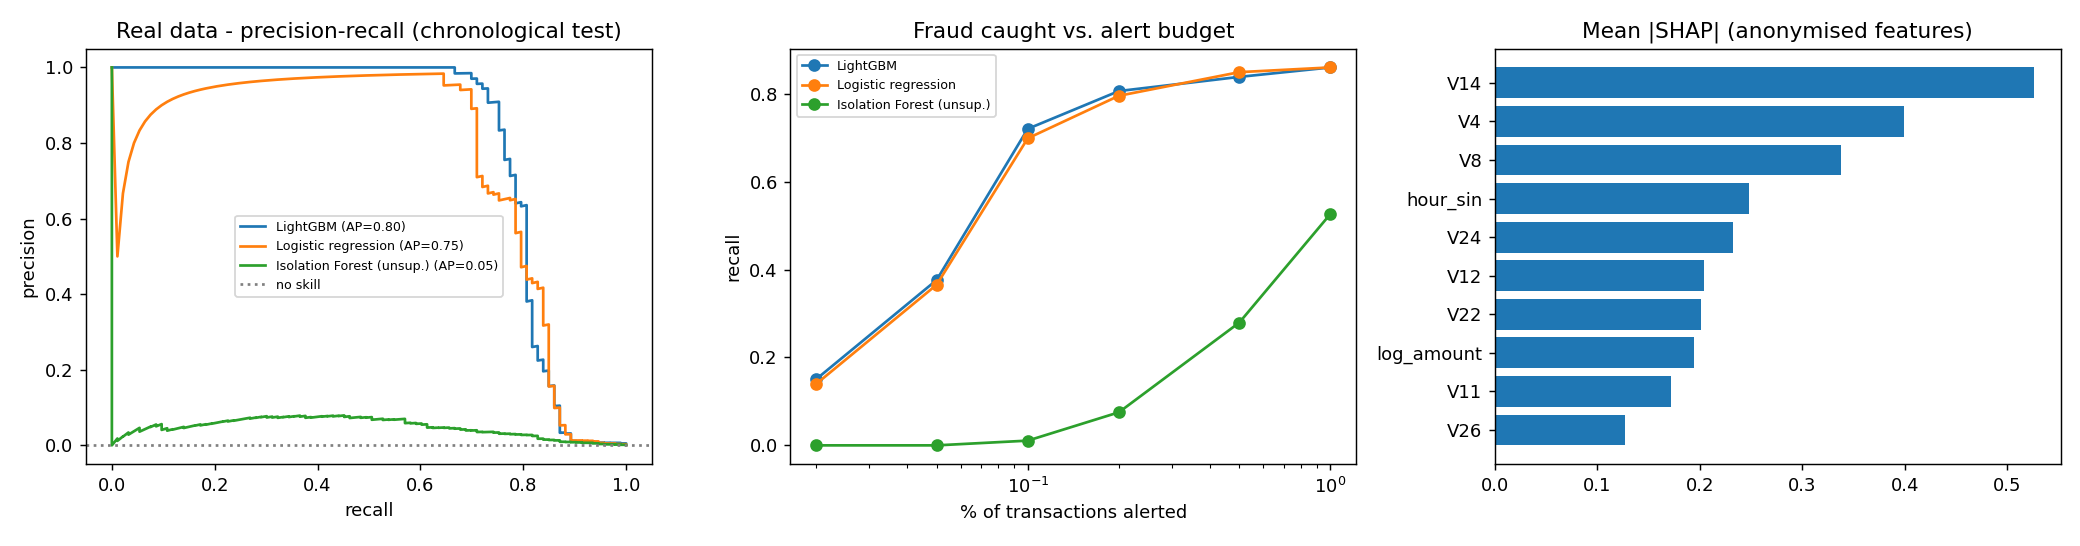

PR-AUC with 95 percent bootstrap CI (only 93 frauds in the test period!):
  LightGBM             0.803  [0.7228, 0.8825]
  Logistic regression  0.750  [0.6467, 0.8579]
  paired difference    +0.054  [0.0009, 0.1178]


In [2]:
d = real["dataset"]; print(f"{d['rows']:,} rows after dropping {d['duplicates_dropped']:,} exact duplicates | {d['fraud']} frauds ({d['fraud_rate']:.2%}) | frauds by split {d['frauds_by_split']}")
tbl = pd.DataFrame(real["models"]).T[["pr_auc", "roc_auc", "recall@0.05%_alerts", "recall@0.10%_alerts", "recall@0.50%_alerts", "value_recall@0.10%_alerts"]]
display(tbl.round(3))
display(Image(R + "figures/real_data.png"))
b = real["bootstrap_pr_auc_test"]
print(f"PR-AUC with 95 percent bootstrap CI (only {real['dataset']['frauds_by_split']['test']} frauds in the test period!):")
for k in ("LightGBM", "Logistic regression"): print(f"  {k:20s} {b[k]['point']:.3f}  {b[k]['ci95']}")
print(f"  paired difference    {b['paired_diff_lgbm_minus_logreg']['point']:+.3f}  {b['paired_diff_lgbm_minus_logreg']['ci95']}")

In [3]:
sp = real["split_comparison_lgbm_pr_auc"]
print(f"Random stratified split PR-AUC {sp['random_stratified']:.3f}  vs  chronological {sp['chronological']:.3f}  ->  random split OVERSTATES by {sp['random_stratified'] - sp['chronological']:+.3f}")
print("\nCalibration (Brier; lower is better):", real["calibration"])
display(pd.DataFrame(real["cost_based_alerting_test"]).T)
print("Top features:", real["top_features_mean_abs_shap"])

Random stratified split PR-AUC 0.861  vs  chronological 0.792  ->  random split OVERSTATES by +0.069

Calibration (Brier; lower is better): {'brier_raw': 0.000384, 'brier_calibrated': 0.000382, 'brier_no_skill': 0.00131}


,alert_rate,recall,precision,loss_without_model,loss_with_model,savings_pct
alert_cost=1,0.00650,0.849,0.171,10837.5,2824.1,73.9
alert_cost=5,0.00627,0.849,0.178,10837.5,4588.1,57.7
alert_cost=25,0.00094,0.699,0.970,10837.5,5371.1,50.4


Top features: {'V14': 0.5257, 'V4': 0.3993, 'V8': 0.3378, 'hour_sin': 0.2479, 'V24': 0.2324, 'V12': 0.2037, 'V22': 0.201, 'log_amount': 0.1944}


**What this shows - and the honest reading**
* On **real** data a chronological split gives a materially lower score than a random split (~0.07 PR-AUC): time-based validation is not optional.
* LightGBM beats logistic regression, but the paired gain is small and its CI barely excludes zero - with 93 test frauds the data cannot support strong claims. In my simulated world the gap is huge (+0.25); that says more about my generator's feature interactions than about real fraud.
* The unsupervised Isolation Forest is almost useless in precision terms (PR-AUC ~0.05): "unusual" is not "fraudulent".
* Cost-based alerting works: choosing the threshold by expected loss (a missed fraud costs its amount, each alert costs a fixed review fee) saves 50-74% of fraud loss depending on review cost.
* `hour_sin` ranks 4th in importance, but the data covers only 48 hours: a time-of-day effect learned from two days may be coincidence. An ablation on a longer history would be the first follow-up.
* A model with this little data needs wide intervals reported next to every number.

## 2. Are the headline numbers luck? (simulated UPI world)

In [4]:
c = rob["cluster_bootstrap_test"]
print(f"Cluster bootstrap: resample whole SENDERS ({c['n_clusters']:,} clusters; {c['n_fraud']:,} frauds; {c['n_boot']} resamples) because fraud arrives in bursts, so rows are not independent.\n")
rows = {k: {"PR-AUC": f"{v['pr_auc']['point']:.3f}  {v['pr_auc']['ci95']}", "recall @ rules' flag rate": f"{v['recall_at_rules_flag_rate']['point']:.3f}  {v['recall_at_rules_flag_rate']['ci95']}"} for k, v in c.items() if isinstance(v, dict) and "pr_auc" in v}
rows["Hand-written rules"] = {"PR-AUC": "-", "recall @ rules' flag rate": f"{c['rules']['recall']['point']:.3f}  {c['rules']['recall']['ci95']}"}
display(pd.DataFrame(rows).T)
for k, v in c.items():
    if k.startswith("paired"): print(f"{k}: {v['point']:+.3f}  95% CI {v['ci95']}")
lg, rl = c["LightGBM"], c["rules"]
print(f"\nAt the rule set's alert volume ({rl['flag_rate']:.2%} of payments): LightGBM recall {lg['recall_at_rules_flag_rate']['point']:.2f} vs rules {rl['recall']['point']:.2f} -> {lg['recall_at_rules_flag_rate']['point'] / rl['recall']['point']:.1f}x")

Cluster bootstrap: resample whole SENDERS (11,706 clusters; 2,743 frauds; 400 resamples) because fraud arrives in bursts, so rows are not independent.



,PR-AUC,recall @ rules' flag rate
LightGBM,"0.945 [0.9325, 0.957]","0.768 [0.7137, 0.8131]"
LogisticRegression,"0.691 [0.6475, 0.731]","0.533 [0.495, 0.5717]"
Hand-written rules,-,"0.276 [0.2355, 0.3128]"


paired_diff_pr_auc_LightGBM_minus_LogisticRegression: +0.254  95% CI [0.2161, 0.2965]
paired_diff_recall_LightGBM_minus_rules: +0.492  95% CI [0.4408, 0.5464]

At the rule set's alert volume (1.38% of payments): LightGBM recall 0.77 vs rules 0.28 -> 2.8x


In [5]:
ms = rob["multi_seed"]; t = pd.DataFrame(ms["per_seed"]).set_index("seed").round(3); display(t)
print("mean:", {k: v for k, v in ms["mean"].items() if k.startswith(("lgbm", "logreg", "rules"))})
print("std :", {k: v for k, v in ms["std"].items() if k.startswith(("lgbm", "logreg", "rules"))})

,fraud_rate,test_fraud,lgbm_pr_auc,logreg_pr_auc,lgbm_recall_at_rules_rate,rules_recall
seed,,,,,,
11,0.016,482,0.956,0.654,0.820,0.228
12,0.016,537,0.951,0.610,0.730,0.160
13,0.016,505,0.945,0.554,0.679,0.202
14,0.017,482,0.951,0.646,0.817,0.237
15,0.017,530,0.908,0.633,0.757,0.232


mean: {'lgbm_pr_auc': 0.9422, 'logreg_pr_auc': 0.6194, 'lgbm_recall_at_rules_rate': 0.7605, 'rules_recall': 0.2118}
std : {'lgbm_pr_auc': 0.0197, 'logreg_pr_auc': 0.04, 'lgbm_recall_at_rules_rate': 0.0597, 'rules_recall': 0.0318}


**Reading:** the cluster-bootstrap intervals are tight and five freshly generated worlds (small preset) agree, so the simulated-system result is not an accident of one random draw: LightGBM sits near 0.94 PR-AUC, far above logistic regression, and catches roughly 2.8x as much fraud as the rules at the same alert volume.
It is still a statement about *my* generator. Section 1 is the check against reality - note how much lower the real-data number is.

## 3. Do conclusions depend on my cost assumptions?

,savings_pct_fixed_thresholds,savings_pct_reoptimised,flag_rate_reoptimised
baseline,99.0,99.0,0.0450
review_cost x0.5,99.0,99.0,0.0450
review_cost x2,98.9,98.9,0.0450
review_catch -25%,98.6,98.6,0.0450
review_catch +25%,99.3,99.6,0.0450
stepup_cost x0.5,99.0,99.0,0.0450
stepup_cost x2,98.9,98.9,0.0450
stepup_catch -25%,98.6,98.6,0.0450
stepup_catch +25%,99.1,99.1,0.0450
stepup_abandon x0.5,99.0,99.0,0.0450


range of savings across ALL scenarios (re-optimised thresholds): [98.1, 99.6] %


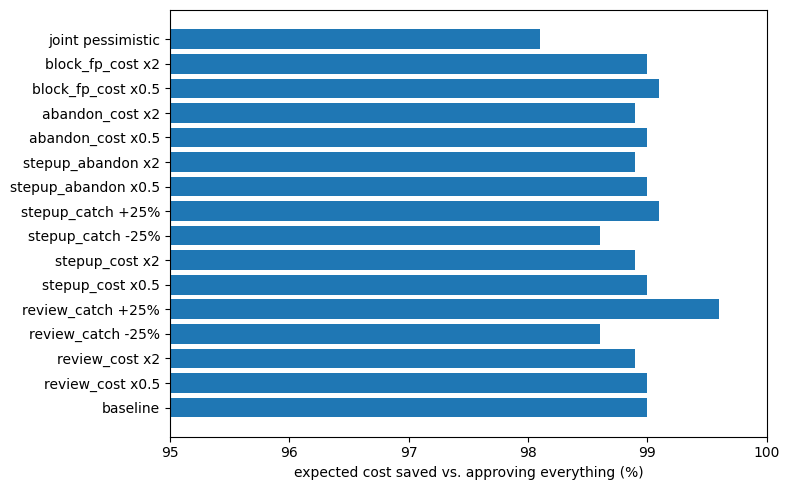

In [6]:
cs = {k: v for k, v in rob["cost_sensitivity"].items() if not k.startswith("_")}
t = pd.DataFrame(cs).T[["savings_pct_fixed_thresholds", "savings_pct_reoptimised", "flag_rate_reoptimised"]].astype(float)
display(t)
print("range of savings across ALL scenarios (re-optimised thresholds):", rob["cost_sensitivity"]["_range_savings_pct_reoptimised"], "%")
fig, ax = plt.subplots(figsize=(8, 5)); ax.barh(t.index, t.savings_pct_reoptimised, color="#1f77b4"); ax.set_xlim(95, 100); ax.set_xlabel("expected cost saved vs. approving everything (%)"); plt.tight_layout(); plt.show()

**Reading:** the savings percentage barely moves (about 98-99.6%) even when every cost is halved or doubled, or all are made pessimistic at once, because the avoided fraud amounts dwarf the intervention costs *in this simulated world*.
That is a robustness result, but also a warning: **real prevalence is 10-100x lower**, so false-alert costs would weigh far more and real savings would be much smaller. Treat the percentage as a demonstration of method, not a forecast.

## 4. Fraudsters adapt and labels arrive late: backtest
A new tactic (`novel_merchant_scam`: victims paying a few entertainment/top-up merchants 2-6x their norm from their own device) appears two-thirds of the way through 12 simulated weeks (small-preset world).
Three policies are evaluated weekly: **static** (never retrained), **delayed retrain** (weekly, but only labels at least 7 days old - what production can do), **oracle** (instant labels - unattainable).

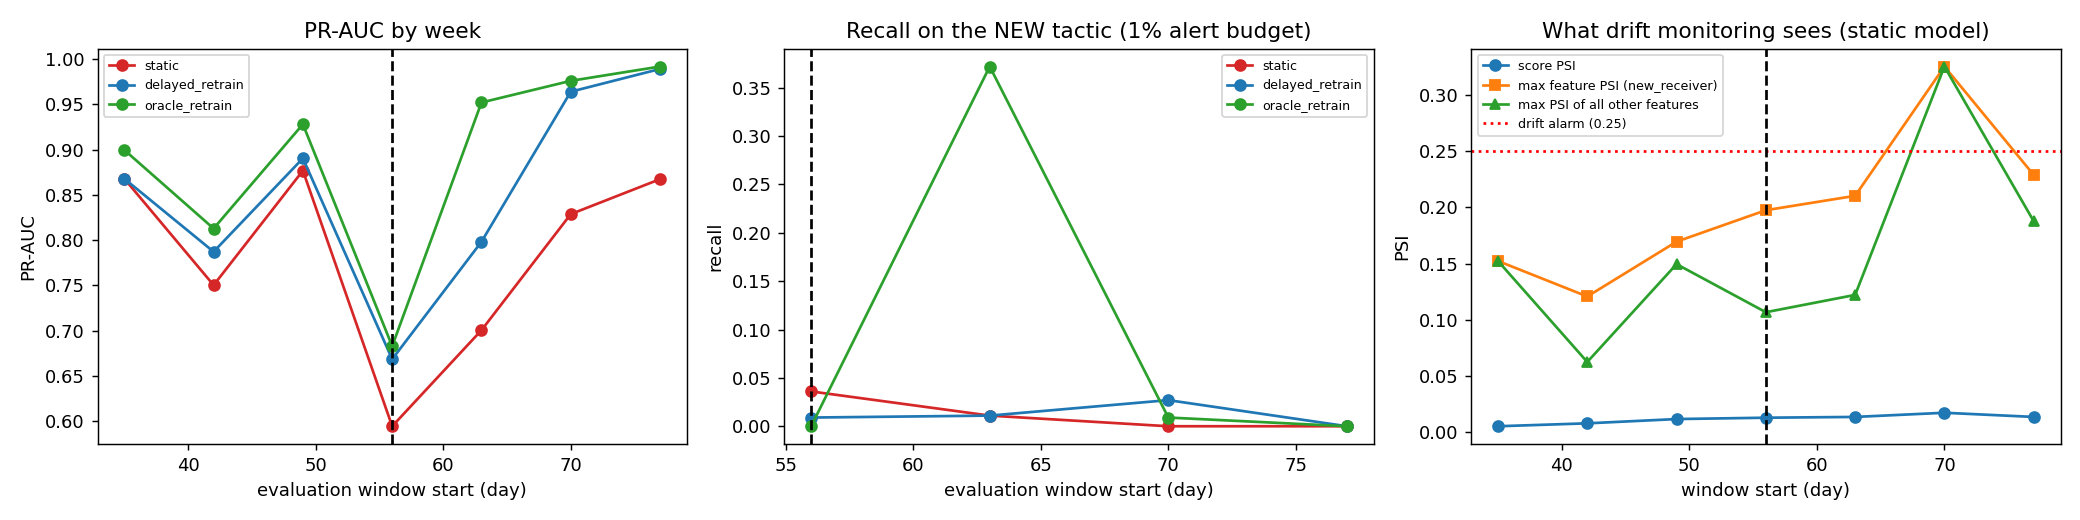

policy,static,delayed_retrain,oracle_retrain
start_day,,,
35,0.868,0.868,0.900
42,0.750,0.787,0.813
49,0.877,0.890,0.928
56,0.595,0.669,0.683
63,0.701,0.798,0.952
70,0.829,0.964,0.976
77,0.867,0.989,0.992


Post-drift summary:


,mean_pr_auc,mean_novel_recall,mean_novel_recall_3pct_budget
delayed_retrain,0.8549,0.012,0.582
oracle_retrain,0.9006,0.095,0.778
static,0.7478,0.012,0.233


In [7]:
display(Image(R + "figures/backtest.png"))
t = pd.DataFrame(bt["rows"])
piv = t.pivot(index="start_day", columns="policy", values="pr_auc")[["static", "delayed_retrain", "oracle_retrain"]]
display(piv.round(3))
print("Post-drift summary:"); display(pd.DataFrame(bt["summary_post_drift"]).T)

In [8]:
s = t[t.policy == "static"][["start_day", "score_psi_vs_train", "max_feature_psi_vs_train", "top_psi_feature", "max_psi_excl_new_receiver"]].round(3)
display(s.reset_index(drop=True))

,start_day,score_psi_vs_train,max_feature_psi_vs_train,top_psi_feature,max_psi_excl_new_receiver
0,35,0.005,0.152,sender_cnt_24h,0.152
1,42,0.008,0.121,new_receiver,0.062
2,49,0.012,0.170,new_receiver,0.150
3,56,0.013,0.198,new_receiver,0.107
4,63,0.014,0.210,new_receiver,0.122
5,70,0.017,0.325,recv_new_payers_24h,0.325
6,77,0.014,0.229,new_receiver,0.188


**Findings**
1. **The first week of a new tactic hurts every policy** (PR-AUC falls from ~0.88-0.93 to 0.60-0.68): no model, even with instant labels, can detect what it has never seen. Rules, limits and anomaly detectors must cover this window.
2. **Label delay costs roughly one extra window.** The oracle is back at ~0.95 PR-AUC one window after onset; the delayed policy is at ~0.80 then and ~0.96 the window after. The static model never fully recovers (0.70-0.87).
3. **Alert capacity decides whether a new tactic is findable.** At a strict 1% alert budget recall on the new tactic stays <= 10% for every policy; at a 3% budget it is ~23% (static), ~58% (delayed retrain) and ~78% (oracle). Retraining only pays off if there is capacity to surface the new pattern.
4. **Monitoring was late or blind.** Score-distribution PSI never exceeded 0.02 (no alarm). Feature PSI first crossed the 0.25 alarm line two weeks after onset (day 70), on `recv_new_payers_24h` - the real signature of many victims paying the same few merchants. Before that, `new_receiver` hovered at 0.06-0.15 purely from benign payee-history accumulation.
   -> Combine input drift with outcome-based monitoring (analyst-confirmed precision, chargebacks), keep a challenger model, and use bounded look-back windows for history features.

## 5. Training/serving parity and latency

In [9]:
from src.features import FEATURES
from src.features import build_features
from src.online import OnlineFeatureStore
df = pd.read_parquet("../data/transactions.parquet").iloc[:40000]
batch = build_features(df).set_index("txn_id"); online = OnlineFeatureStore.replay(df).set_index("txn_id")
diff = pd.Series({f: np.abs(batch[f].to_numpy(float) - online[f].to_numpy(float)).max() for f in FEATURES})
print(f"Replayed {len(df):,} transactions through the streaming store. Max |batch - online| per feature ({len(FEATURES)} features):")
print(diff.round(12).to_string()); print("\nLargest discrepancy anywhere:", diff.max())
display(pd.DataFrame({k: v for k, v in lat.items() if isinstance(v, dict)}).T)
print(lat["note"], "| history rows:", f"{lat['history_rows']:,}")

Replayed 40,000 transactions through the streaming store. Max |batch - online| per feature (25 features):
log_amount             0.0
amount_z               0.0
amount_ratio           0.0
log_time_gap           0.0
sender_cnt_10m         0.0
sender_cnt_1h          0.0
sender_cnt_24h         0.0
recv_cnt_1h            0.0
recv_cnt_24h           0.0
hour                   0.0
is_night               0.0
new_receiver           0.0
new_device             0.0
is_p2p                 0.0
is_collect             0.0
is_round               0.0
geo_speed_log          0.0
new_city               0.0
near_limit             0.0
sender_new_rcv_24h     0.0
recv_new_payers_24h    0.0
merch_cat              0.0
recv_acct_age_log      0.0
sender_acct_age_log    0.0
dow                    0.0

Largest discrepancy anywhere: 4.4142467459096224e-13


,p50_ms,p95_ms,p99_ms,mean_ms
live_score_only,2.94,4.18,4.90,3.14
live_with_shap,5.27,7.17,8.46,5.47
point_in_time_with_shap,71.69,392.35,449.19,110.17


single CPU core, in-process (no HTTP overhead); live path = O(1) store lookups + one LightGBM predict | history rows: 741,063


The streaming store reproduces all 25 training features (the largest difference is float rounding), so there is no training/serving skew. With ~740k history rows, live scoring takes ~5 ms median / ~8 ms p99 with SHAP explanations, versus ~72 ms / ~449 ms for re-scanning history - and the gap widens as history grows, because the store's cost does not depend on it.

## 6. Who bears the false positives?

In [10]:
for dim, v in M["fairness"].items():
    print(f"== {dim}: adverse-impact ratio {v['adverse_impact_ratio']}, chi-square p = {v['homogeneity_p_value']}  ->  {'SIGNIFICANT' if v['significant'] else 'not significant'}")
    display(pd.DataFrame(v["segments"]).T[["n", "genuine_flagged", "genuine_review_block_rate", "rate_ci95", "fraud_recall"]])

== age_band: adverse-impact ratio 1.08, chi-square p = 0.9525  ->  not significant


,n,genuine_flagged,genuine_review_block_rate,rate_ci95,fraud_recall
18-29,32697,59,0.00182,"[0.00141, 0.00235]",0.986
30-44,42079,74,0.00179,"[0.00143, 0.00225]",0.987
45-59,39099,74,0.00192,"[0.00153, 0.00242]",0.989
60+,43134,82,0.00194,"[0.00156, 0.00241]",0.99


== home_city: adverse-impact ratio 5.26, chi-square p = 0.0663  ->  not significant


,n,genuine_flagged,genuine_review_block_rate,rate_ci95,fraud_recall
Ahmedabad,9776,10,0.00104,"[0.00057, 0.00192]",0.977
Bengaluru,19975,35,0.00177,"[0.00128, 0.00247]",0.992
Chennai,14490,31,0.00218,"[0.00153, 0.00309]",0.983
Delhi,25973,42,0.00165,"[0.00122, 0.00223]",0.994
Guwahati,3684,11,0.00305,"[0.00171, 0.00546]",0.988
Hyderabad,14470,26,0.00183,"[0.00125, 0.00268]",0.986
Jaipur,8219,19,0.00234,"[0.0015, 0.00365]",0.98
Kochi,4951,10,0.00205,"[0.00111, 0.00376]",1.0
Kolkata,11359,20,0.0018,"[0.00117, 0.00278]",0.984
Lucknow,7045,4,0.00058,"[0.00023, 0.00149]",0.987


== tenure: adverse-impact ratio 1.27, chi-square p = 0.0574  ->  not significant


,n,genuine_flagged,genuine_review_block_rate,rate_ci95,fraud_recall
established,63338,100,0.00161,"[0.00132, 0.00196]",0.992
new (<10 prior txns),93671,189,0.00205,"[0.00178, 0.00236]",0.985


== upi_app: adverse-impact ratio 1.06, chi-square p = 0.9403  ->  not significant


,n,genuine_flagged,genuine_review_block_rate,rate_ci95,fraud_recall
app_a,78252,145,0.00189,"[0.0016, 0.00222]",0.99
app_b,55910,104,0.00189,"[0.00156, 0.00229]",0.988
app_c,22847,40,0.00178,"[0.00131, 0.00242]",0.984


**Reading:** four dimensions are audited (age band, home city, account tenure, UPI app). Home city shows a raw ~5x spread in the share of genuine payments sent to review/block, which looks alarming - but each city has only a handful to a few dozen such payments, and the chi-square test gives p = 0.066: not significant after Bonferroni correction (alpha = 0.0125). Tenure is nearer the line (p = 0.057): newer accounts are reviewed somewhat more, which is plausible but not proven.
Attributes are randomly assigned in the simulation, so noise is the right explanation for city. My first audit used raw ratios and **failed the CI gate on noise**; the Wilson intervals + significance test make the gate trip only on disparities that are statistically significant *and* material. On real data the same code would surface genuine segment harm.

## 7. Did hyper-parameter tuning help?

In [11]:
print(json.dumps({k: tune[k] for k in ("n_trials", "cv_pr_auc", "test_pr_auc", "test_paired_diff_tuned_minus_default_ci95", "conclusion")}, indent=1))

{
 "n_trials": 10,
 "cv_pr_auc": {
  "default_params": 0.9426,
  "best_tuned": 0.9441
 },
 "test_pr_auc": {
  "default": 0.9485,
  "tuned": 0.9493
 },
 "test_paired_diff_tuned_minus_default_ci95": [
  -0.0007,
  0.0023
 ],
 "conclusion": "no statistically significant test gain (CV improvement did not transfer) -> keep defaults"
}


Optuna (10 trials, 3 time-aware folds, searched on the most recent 300k rows) improved CV by only ~0.002, and on the untouched test period the paired difference (+0.0008, 95% CI [-0.0007, 0.0023]) straddles zero. The defaults were already near a plateau, so I kept them. Reporting a null result is part of the job.

## 8. Can the model say "I'm not sure"? Conformal prediction
Class-conditional split-conformal sets are fitted on a validation slice and promise a coverage level *if* calibration and test data are exchangeable. Payments whose set holds both classes (or neither) are "uncertain" and natural candidates for a human.

In [12]:
cf = M["conformal"]; print("miss-rate targets:", {k: cf["params"][k] for k in ("alpha_fraud", "alpha_genuine")})
display(pd.Series(cf["test"]).to_frame("test period"))

miss-rate targets: {'alpha_fraud': 0.1, 'alpha_genuine': 0.02}


,test period
coverage_fraud,0.8764
coverage_genuine,0.9789
share_uncertain,0.0200
share_confident_fraud,0.0179
share_confident_genuine,0.9621
fraud_in_uncertain,0.0928
precision_confident_fraud,0.8549


**Reading:** the targets were 90% fraud coverage and 98% genuine coverage; on the chronologically later test period the model achieved ~88% and ~98%. The small shortfall for fraud is the expected cost of **distribution shift** - the calibration slice precedes the test period, so exchangeability does not hold exactly. Only ~2% of payments are uncertain, and confident-fraud calls are ~85% precise. The guarantee is real but degrades quietly under drift - another reason to monitor outcomes.

## 9. What this evidence does and does not establish
**Establishes:** method soundness on real data (chronological validation, calibration, cost-based alerting); stability across resamples and independent worlds; robustness to cost assumptions; zero training/serving skew; a quantified failure mode under drift and label delay; calibrated uncertainty with a visible shift penalty.
**Does not establish:** performance on real UPI data (behavioural identifiers are not public); real-world base rates; adversarial robustness beyond one simulated tactic; production load behaviour (latency measured in-process on one core). Six of the eight simulated typologies are recalled at ~100%, which says the injected signatures are strong - real attackers are subtler.
**Next steps:** shadow-mode deployment, bounded look-back windows for history features, outcome-based monitoring with a challenger model, receiver-side graph embeddings / GNN.